# EL4007 Digital Image Processing

**Quiz 1**  
**Muhammad Akmal | 13524099**

## 0. Soal

Anda berada di suatu tempat di daerah perkotaan dan tidak mengetahui lokasinya. Gunakan kamera HP untuk mengestimasi posisi dan orientasi Anda. Ambil sebuah gambar, kemudian lakukan seluruh proses hingga memperoleh estimasi tersebut.

### 0.1 Aspek Penilaian

1. Dekomposisi masalah.
2. Perolehan koordinat 3D. Asumsi diperbolehkan, tetapi harus dinyatakan dan dijustifikasi.
3. Perolehan koordinat 2D pada gambar, termasuk nama algoritma dan tahapan prosesnya.
4. Penentuan koordinat posisi dan orientasi kamera.
5. Analisis hasil, sumber error, dan keterbatasan solusi.

### 0.2 Berkas yang Dikumpulkan

* Satu Jupyter Notebook berisi source code, deskripsi, tahapan proses, dan analisis hasil.
* Dikumpulkan sebagai repositori GitHub atau berkas ZIP.

## 1. Permasalahan

### 1.1 Deskripsi

Ada seseorang yang tidak tahu di mana ia berada. Ia berada di sebuah *platform* menanjak ke arah sebuah kompleks bangunan perkantoran. Di sisi lainnya, *platform* tersebut menurun ke sebuah lapangan, di mana terdapat sebuah arena yang terdiri dari berbagai macam *gate* berwarna orange. Di kejauhan, terlihat sebuah bangunan raksasa berbentuk rangka logam besar. 

"Tempat ini aneh", pikirnya. Terlihat seperti kota mati, bangunannya masih baru dan megah, tetapi hampir tidak ada orang yang terlihat beraktivitas. Cuacanya juga sangat panas, seperti matahari ada tepat di atas kepala. Anginnya tidak membantu, membuat udara terasa menyengat dan gerah. 

Ia membuka *smartphone*-nya, lalu menyadari bahwa ia tidak mendapatkan sinyal GPS. Ia pun memotret sebuah gambar, menyadari mungkin dapat berguna nanti. Sembari melihat galerinya, ia menyadari bahwa ia mendapatkan sebuah denah yang sangat menarik. Setelah diteliti, ternyata itu adalah cetak biru untuk arena yang saat ini ia lihat, meski rupanya di-*mirror*[^1]. Ia pun penasaran, seberapa jauh ia dari arena ini? Ia ingin mengestimasi pose (posisi dan orientasi) gambar yang baru saja ia ambil relatif terhadap arena tersebut?

![Gambar yang diambil](./assets/image.jpg)  
Deskripsi: Gambar utama sebagai sumber estimasi pose.

[^1]: Referensi cetak biru ini krusial untuk mengetahui ukuran asli objek. Lihat denah di bawah.

### 1.2 Identifikasi Objek

Dari gambar, dapat diientifikasi **objek-objek yang relevan** sebagai berikut:
* *Single Gate* berwarna oranye, selanjutnya disebut SG.
* *Double Gate* berwarna oranye berbentuk terowongan, selanjutnya disebut DG.
* *Triple Gate* berwarna oranye berbentuk terowongan yang lebih panjang dari DG, selanjutnya disebut TG.
* *Waypoint* berwarna kuning di depan arah masuk-keluar *gate*, selanjutnya disebut WP.
* *Kotak merah* di tengah salah satu WP.
* *Garis hitam-kuning* yang menandai batas-batas arena di lapangan. 

Untuk memudahkan, pusat *world frame* akan didefinisikan sebagai titik tengah pada WP di mana kotak merah berada. Estimasi pose akan dilakukan untuk mendefinisikan posisi kamera relatif terhadap pusat kamera tersebut. Selain itu, karena pendekatan dilakukan dengan metode PnP (Perspective-n-Point), diperlukan referensi ukuran dan tatak letak 3D objek referensi. Berikut adalah model penuh yang akan digunakan sebagai referensi, dengan tata letak perlu di-*mirror* karena gambar menggunakan lapangan di sebelah kiri. 

![Model Lapangan](./assets/model.png)  
Deskripsi: Tampilan model 3D lapangan. Bagian kiri/merah adalah area yang dipotret. Model hanya untuk ilustrasi, tidak benar-benar akurat.  
Catatan: Pada gambar asli, warna landing zone adalah merah. Terjadi perbedaan warna di lapangan, tetapi tetap menggunakan model kiri.

![Tata letak Lapangan](./assets/layout.png)  
Deskripsi: Tata letak lapangan pada bagian kanan. Posisi akan di-*mirror* untuk bagian kiri.



## 2. Input dan Asumsi

### 2.1 Metadata Gambar (EXIF)

- **Camera**
  - Make: samsung
  - Model: Galaxy A55 5G
  - XResolution: 72
  - YResolution: 72
  - ResolutionUnit: Inch
  - Software: A556EXXSHDZH6
  - XResolution: 72
  - YResolution: 72
  - ResolutionUnit: Inch
  - ExifVersion: Exif Version 2.2
  - FocalLengthIn35mmFilm: 23
- **Image Data**
  - ImageWidth: 4080
  - ImageLength: 2296
  - Orientation: Right-top
  - DateTime: 2026:09:22 13:52:09
  - YCbCrPositioning: Centered
  - ImageWidth: 512
  - ImageLength: 288
  - Compression: JPEG compression
  - ISOSpeedRatings: 50
  - DateTimeOriginal: 2026:09:22 13:52:09
  - DateTimeDigitized: 2026:09:22 13:52:09
  - PixelXDimension: 4080
  - PixelYDimension: 2296
- **Image Taking Conditions**
  - ExposureTime: 1/3356 sec.
  - FNumber: f/1.8
  - ExposureProgram: Normal program
  - ShutterSpeedValue: 0.00 EV (1/1 sec.)
  - ApertureValue: 1.69 EV (f/1.8)
  - BrightnessValue: 9.72 EV (2889.56 cd/m^2)
  - ExposureBiasValue: 0.00 EV
  - MaxApertureValue: 1.69 EV (f/1.8)
  - MeteringMode: Center-weighted average
  - Flash: Flash did not fire
  - FocalLength: 5.5 mm
  - ExposureMode: Auto exposure
  - WhiteBalance: Auto white balance
  - DigitalZoomRatio: 1.00
  - SceneCaptureType: Standard
- **Other**
  - OffsetTime: +08:00
  - OffsetTimeOriginal: +08:00
  - SubsecTime: 210
  - SubSecTimeOriginal: 210
  - SubSecTimeDigitized: 210
  - FlashpixVersion: FlashPix Version 1.0
  - ColorSpace: Uncalibrated

### 2.2 Dimensi Objek

| Model | Keterangan  |
| ------| ----------- |
| ![Single Gate](./assets/single-gate.png) | Single Gate. |
| ![Double Gate](./assets/double-gate.png) | Double Gate. Bagian samping gate ditutup penuh hingga bawah pada gambar asli. |
| ![Triple Gate](./assets/triple-gate.png) | Triple Gate. Bagian samping gate ditutup penuh hingga bawah pada gambar asli. |
| ![Waypoint](./assets/waypoint.png) | Waypoint. ArUco diabaikan, tidak terlihat di gambar. |
| ![Kotak Merah](./assets/red-box.png) | Kotak Merah. Bagian panjang ($l$) menghadap kamera. |


## 3. Dekomposisi Masalah

Pertanyaan "di mana saya dan ke arah mana saya menghadap?" diubah menjadi masalah **Perspective-n-Point (PnP)**: jika diketahui sejumlah titik 3D $X_i$ (dalam meter, pada *world frame*) dan proyeksinya $x_i$ (dalam piksel) pada sebuah kamera dengan parameter kalibrasi intrinsik $K$, cari rotasi $R$ dan translasi $t$ sedemikian sehingga

$$x_i \simeq \pi\big(K\,(R\,X_i + t)\big),$$

dengan $\pi$ adalah pembagian perspektif. Posisi kamera lalu diperoleh dari $C = -R^\top t$ dan orientasinya dari baris-baris $R$.

Masalah tersebut dipecah menjadi sub-masalah yang masing-masing menghasilkan satu keluaran untuk tahap berikutnya, dijelaskan pada subjudul berikut:

| # | Tahap | Masukan | Keluaran |
|---|---|---|---|
| 4 | Koordinat 3D | denah (mm), gambar dimensi *gate* | titik 3D dinamai sesuai *world frame* (m) |
| 5 | Intrinsik kamera | EXIF (Metadata Gambar) | matriks $K$ dan distorsi |
| 6 | Koordinat 2D | gambar asli | titik piksel bernama dengan ketidakpastian $\sigma$ |
| 7 | Korespondensi | hasil 4 dan 6 | pasangan $(X_i, x_i)$, dibagi menjadi set *pose*, *hold-out*, dan *analisis* |
| 8 | Estimasi pose | pasangan titik, $K$ | $R$, $t$, posisi $C$, *heading/pitch/roll* |
| 9 | Validasi | pose dan titik *hold-out* | bukti dan verifikasi pose konsisten |
| 10 | Analisis error | semua sumber ketidakpastian | $\pm\sigma$ untuk setiap komponen pose |
| 11 | Kesimpulan | hasil semuanya | jawaban akhir dan keterbatasan |

### 3.1 Konvensi koordinat

Untuk memastikan
- **Satuan:** meter (m) di seluruh notebook. Nilai dari denah (mm) dikonversi sekali saat dibaca.
- ***World frame*** `w`: **origin di titik tengah WP yang berisi kotak merah** (selanjutnya WP\* dibaca WP-Star), pada permukaan tanah.
  - $+X$: ke kanan dilihat dari kamera, sejajar baris WP\* - DG - WP kanan.
  - $+Y$: maju menjauhi kamera, dari WP\* ke arah TG.
  - $+Z$: ke atas sesuai aturan tangan kanan ($X \times Y = Z$).
- ***Camera frame*** `c` (konvensi OpenCV): $x$ ke kanan gambar, $y$ ke bawah gambar, $z$ searah sumbu optik.
- **Pose:** $X_c = R\,X_w + t$, sesuai keluaran `cv2.solvePnP`. Posisi kamera: $C_w = -R^\top t$.
- **Sudut yang mudah dibaca:**
  - *heading*: azimut sumbu optik pada bidang tanah, diukur dari $+Y$ ke arah $+X$ (nilai positif berarti menoleh ke kanan).
  - *pitch*: elevasi sumbu optik terhadap bidang horizontal (nilai positif mendongak ke atas).
  - *roll*: rotasi kamera terhadap sumbu optiknya (0 berrti horizon datar, positif,kamera dirotasi searah jarum jam).

In [1]:
import math
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse, Polygon as MplPolygon
from PIL import ExifTags, Image

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
RNG = np.random.default_rng(2026)

ASSETS = Path("assets")
IMAGE_PATH = ASSETS / "image.jpg"


def rot_from_angles(heading, pitch, roll):
    "Rotasi world->camera (OpenCV) dari heading/pitch/roll dalam derajat."
    h, p, r = np.radians([heading, pitch, roll])
    fwd = np.array([math.sin(h) * math.cos(p), math.cos(h) * math.cos(p), math.sin(p)])
    right0 = np.array([math.cos(h), -math.sin(h), 0.0])   # sumbu-x kamera saat roll = 0
    down0 = np.cross(fwd, right0)                           # sumbu-y kamera saat roll = 0
    right = math.cos(r) * right0 + math.sin(r) * down0
    down = -math.sin(r) * right0 + math.cos(r) * down0
    return np.vstack([right, down, fwd])                    # baris berarti sumbu kamera dalam world


def angles_from_rot(R):
    "(heading, pitch, roll) dalam derajat."
    right, down, fwd = R
    heading = math.degrees(math.atan2(fwd[0], fwd[1]))
    pitch = math.degrees(math.asin(np.clip(fwd[2], -1.0, 1.0)))
    roll = math.degrees(math.atan2(-right[2], -down[2]))
    return heading, pitch, roll


def camera_centre(R, t):
    return -R.T @ np.asarray(t, float).reshape(3)


# Testing: kamera datar menghadap +Y, lalu round-trip dengan random angle
assert np.allclose(rot_from_angles(0, 0, 0), [[1, 0, 0], [0, 0, -1], [0, 1, 0]])
for hpr in [(5, 6, -1), (-30, -10, 3), (120, 20, 0.5)]:
    R_test = rot_from_angles(*hpr)
    assert np.allclose(R_test @ R_test.T, np.eye(3)) and np.isclose(np.linalg.det(R_test), 1)
    assert np.allclose(angles_from_rot(R_test), hpr)
print("Uji konvensi lolos.")

Uji konvensi lolos.


## 4. Perolehan Koordinat 3D

### 4.1 Asumsi

Berikut adalah daftar asumsi yang digunakan untuk menyelesaikan masalah ini. Masing-masing akan direferensikan sesuai ID-nya dan akan diverifikasi.

| ID | Asumsi | Justifikasi | Dampak | Pengujian |
|---|---|---|---|---|
| A1 | Lapangan yang difoto adalah benar-benar cerminan (*mirror*) kiri-kanan dari denah | Dari gambar, urutan objek pada foto cocok dengan versi yang di-*mirror* | Jika salah, korespondensi salah total | Bagian 7, 9 |
| A2 | Garis dimensi pada denah mengacu ke tepi WP dan bidang muka/rangka *gate* | Ekstensi garis dimensi pada denah jatuh tepat di tepi simbol | Jika berbeda, mungkin terjadi pergeseran < 0,1 m per objek | Bagian 9.2 |
| A3 | TG dan WP belakang segaris (sumbu $X$ sama) | Terlihat segaris pada denah, tetapi tidak ada dimensi eksplisit | Jika salah, akan ada pergeseran lateral TG | Bagian 9.2, 10 |
| A4 | *Gate* dibuat sesuai gambar dimensi | Referensi gambar | Jika salah, terjadi bias skala derajat jarak | Bagian 10 |
| A5 | Tanah datar, alas *gate* di $Z = 0$ | Area latihan terlihat rata | Bias tinggi pitch jika tidak rata | Bagian 9 |
| A6 | Area dekat (WP\*, DG, TG) terpasang sesuai denah, dengan toleransi ~0,2 m | Jarak antarobjek hanya ~1 m sehingga mudah dipasang tepat | Bias langsung pada posisi kamera jika tidak tepat | Bagian 9.2, 10 |
| A7 | Model kamera *pinhole*, distorsi sudah dikoreksi oleh *smartphone*, dan *principal point* di tengah | Konvensi dari kamera umum di HP | Jika tidak tepat, risiko terjadi residual radial dengan bias rotasi kecil | Bagian 9.1, 10 |
| A8 | Nilai `FocalLengthIn35mmFilm` mengacu ke diagonal sensor 4:3 penuh (gambar berdimensi 16:9 karena *crop*) | Konsisten dengan `FocalLength` = 5,5 mm dan ukuran sensor ponsel | Error skala jarak jika berbeda | Bagian 5, 10 |

### 4.2 Pembacaan denah

Denah (bagian biru) dibaca dalam koordinat *as drawn*: origin di pojok kiri-bawah, $x$ ke kanan, $y$ ke atas. Setiap angka di bawah menyesuaikan dimensi yang tertulis pada denah.

In [24]:
MM = 1e-3
FIELD_W_MM, FIELD_L_MM = 40000.0, 60000.0
WP_MM = 2000.0                                # sisi waypoint
GATE_W, DG_DEPTH, TG_DEPTH = 1900.0, 1000.0, 2000.0

# --- baris bawah: WP kiri | DG | WP kanan (as drawn) 
x_wp_a = 12000.0                              # "12000": tepi kiri lapangan -> tepi kiri WP kiri
x_dg = x_wp_a + WP_MM + 994.9                 # "994.9": WP kiri -> sisi DG
x_wp_b = x_dg + DG_DEPTH + 994.7              # "994.7": sisi DG -> WP kanan (= WP*, WP kotak merah)
y_row = 10000.0                               # "10000": tepi bawah lapangan -> tepi bawah baris WP

# --- kolom di atas WP*: TG lalu WP berikutnya 
y_tg_front = y_row + WP_MM + 1000.0           # "1000": WP* -> depan TG
y_tg_back = y_tg_front + TG_DEPTH
y_wp_c = y_tg_back + 1000.0                   # "1000": TG -> WP berikutnya (tepi bawah)

# --- jalur diagonal ke WP jauh di ujung + SG ujung
x_wp_far = x_wp_b + WP_MM + 3000.0            # "3000": tepi kanan kolom WP*/TG -> tepi kiri WP jauh
y_wp_far = y_wp_c + WP_MM + 9000.0            # "9000": WP di belakang TG -> WP jauh
y_sg_far = y_wp_far + WP_MM + 999.6           # "999.6": WP jauh -> SG jauh

plan = pd.DataFrame([
    # id        jenis       center x (mm)                  center y (mm)              keterangan
    ("WP*",    "waypoint", x_wp_b + WP_MM / 2,           y_row + WP_MM / 2,        "origin world frame"),
    ("DG",     "double",   x_dg + DG_DEPTH / 2,          y_row + WP_MM / 2,        "bukaan menghadap +x"),
    ("WP_E",   "waypoint", x_wp_a + WP_MM / 2,           y_row + WP_MM / 2,        "WP di sisi lain DG"),
    ("TG",     "triple",   x_wp_b + WP_MM / 2,           y_tg_front + TG_DEPTH / 2, "bukaan menghadap +y"),
    ("WP_C",   "waypoint", x_wp_b + WP_MM / 2,           y_wp_c + WP_MM / 2,       "di belakang TG"),
    ("WP_far", "waypoint", x_wp_far + WP_MM / 2,         y_wp_far + WP_MM / 2,     "ujung jalur diagonal"),
    ("SG_far", "single",   x_wp_far + WP_MM / 2,         y_sg_far,                 "di belakang WP_far"),
    ("SG_a",   "single",   9993.9 + GATE_W / 2,          20000.0,                  '"9993.9" & "20000"'),
    ("SG_b",   "single",   4994.1 + GATE_W / 2,          30000.0,                  '"4994.1" & "30000"'),
], columns=["id", "jenis", "x_plan_mm", "y_plan_mm", "keterangan"]).set_index("id")

assert plan.x_plan_mm.between(0, FIELD_W_MM).all() and plan.y_plan_mm.between(0, FIELD_L_MM).all()
plan

,jenis,x_plan_mm,y_plan_mm,keterangan
id,,,,
WP*,waypoint,17989.6,11000.0,origin world frame
DG,double,15494.9,11000.0,bukaan menghadap +x
WP_E,waypoint,13000.0,11000.0,WP di sisi lain DG
TG,triple,17989.6,14000.0,bukaan menghadap +y
WP_C,waypoint,17989.6,17000.0,di belakang TG
WP_far,waypoint,22989.6,28000.0,ujung jalur diagonal
SG_far,single,22989.6,29999.6,di belakang WP_far
SG_a,single,10943.9,20000.0,"""9993.9"" & ""20000"""
SG_b,single,5944.1,30000.0,"""4994.1"" & ""30000"""


### 4.3 Transformasi denah ke *world frame*

Foto diambil di lapangan kiri, yaitu cerminan lapangan kanan terhadap garis tengah. Mirror kiri-kanan $x \mapsto W - x$ diikuti pergeseran origin ke WP\* menghasilkan

$$X = \frac{x_{WP^*} - x}{1000}, \qquad Y = \frac{y - y_{WP^*}}{1000}, \qquad Z = z .$$

Lebar lapangan $W$ saling meniadakan, jadi hanya posisi relatif yang berpengaruh. Mirror hanya diterapkan pada penentuan posisi. Geometri lokal *gate* tidak di-*mirror*, karena *gate* fisiknya tidak berubah. Kamera melihat ke arah $+Y$, sehingga $-X$ selalu berada di kiri gambar.

In [25]:
ref = plan.loc["WP*"]
plan["X"] = (ref.x_plan_mm - plan.x_plan_mm) * MM
plan["Y"] = (plan.y_plan_mm - ref.y_plan_mm) * MM
plan[["jenis", "X", "Y", "keterangan"]]

,jenis,X,Y,keterangan
id,,,,
WP*,waypoint,0.000,0.0,origin world frame
DG,double,2.495,0.0,bukaan menghadap +x
WP_E,waypoint,4.990,0.0,WP di sisi lain DG
TG,triple,0.000,3.0,bukaan menghadap +y
WP_C,waypoint,0.000,6.0,di belakang TG
WP_far,waypoint,-5.000,17.0,ujung jalur diagonal
SG_far,single,-5.000,19.0,di belakang WP_far
SG_a,single,7.046,9.0,"""9993.9"" & ""20000"""
SG_b,single,12.045,19.0,"""4994.1"" & ""30000"""


### 4.4 Geometri lokal objek

Untuk *gate*, dari dimensi didapatkan rangka (*frame*) depan memiliki lebar $1900$ mm dan tinggi total $2000$ mm, bukaan $1500 \times 1500$ mm. Maka, lebar rangka $\frac{1900-1500}{2} = 200$ mm, dan ujung bawah panel berada di $2000 - 200 - 1500 = 300$ mm (sisanya kaki). Untuk kotak merah, dari ukuran $620 \times 415 \times 145$ mm, sisi panjang (620 mm) menghadap kamera ($\parallel X$). WP berukuran $2000 \times 2000$ mm dengan tebal diabaikan.

Konvensi penamaan: 
- `o`/`i` = sisi luar (outside) / dalam (inside)
- `T`/`B` = atas (top) / bawah (bottom)
- `L`/`R` = kiri (left) / kanan (right) dilihat dari kamera

Setiap titik memiliki peran sebagai berikut:
- `pose`: dipakai menghitung pose (klaster dekat TG + DG)
- `holdout`: tidak dipakai menghitung pose, hanya untuk validasi (WP\*, kotak merah, WP_E)
- `analisis`: single *gate*, hanya untuk analisis konsistensi denah

In [26]:
HW, HI = 0.95, 0.75                  # setengah lebar luar / dalam rangka (m)
Z_TOP, Z_IN_TOP, Z_PANEL_BOT = 2.00, 1.80, 0.30


def frame_corners(xc, y):
    "8 sudut rangka muka sebuah gate yang menghadap +Y, berpusat di X = xc, bidang muka di Y = y."
    return {
        "oTL": (xc - HW, y, Z_TOP), "oTR": (xc + HW, y, Z_TOP),
        "iTL": (xc - HI, y, Z_IN_TOP), "iTR": (xc + HI, y, Z_IN_TOP),
        "oBL": (xc - HW, y, Z_PANEL_BOT), "iBL": (xc - HI, y, Z_PANEL_BOT),
        "oBR": (xc + HW, y, Z_PANEL_BOT), "iBR": (xc + HI, y, Z_PANEL_BOT),
    }


def square_corners(xc, yc, half=1.0, z=0.0):
    "Sudut WP: F = jauh (+Y), N = dekat (-Y)."
    return {"FL": (xc - half, yc + half, z), "FR": (xc + half, yc + half, z),
            "NR": (xc + half, yc - half, z), "NL": (xc - half, yc - half, z)}


def build_model(plan):
    rows = []
    def add(obj, pts, role):
        for name, p in pts.items():
            rows.append((f"{obj}_{name}", obj, role, *p))

    tg = plan.loc["TG"]
    tg_front = tg.Y - TG_DEPTH * MM / 2
    tg_back = tg.Y + TG_DEPTH * MM / 2
    
    add("TG", frame_corners(tg.X, tg_front), "pose")
    add("TG", {"bTL": (tg.X - HW, tg_back, Z_TOP)}, "pose")          # pojok atas-belakang-kiri (siluet)

    dg = plan.loc["DG"]; x_near = dg.X - DG_DEPTH * MM / 2; x_far = dg.X + DG_DEPTH * MM / 2
    add("DG", {
        "nTL": (x_near, dg.Y - HW, Z_TOP),      # panel samping dekat (-Y), atas, sisi bukaan -X
        "nTR": (x_far, dg.Y - HW, Z_TOP),       # panel samping dekat, atas, sisi +X
        "fT": (x_near, dg.Y + HW, Z_TOP),       # muka bukaan -X, pojok atas jauh (siluet)
        "fiT": (x_near, dg.Y + HI, Z_IN_TOP),   # muka bukaan -X, sudut atas bukaan, jauh
        "niT": (x_near, dg.Y - HI, Z_IN_TOP),   # muka bukaan -X, sudut atas bukaan, dekat
    }, "pose")

    wp = plan.loc["WP*"]
    add("WP*", square_corners(wp.X, wp.Y), "holdout")
    add("RB", {                                                    # kotak merah di tengah WP*
        "TL": (wp.X - 0.31, wp.Y + 0.2075, 0.145), "TR": (wp.X + 0.31, wp.Y + 0.2075, 0.145),
        "BL": (wp.X - 0.31, wp.Y - 0.2075, 0.0), "BR": (wp.X + 0.31, wp.Y - 0.2075, 0.0),
    }, "holdout")
    we = plan.loc["WP_E"]
    add("WP_E", square_corners(we.X, we.Y), "holdout")

    for g in ("SG_far", "SG_a", "SG_b"):
        s = plan.loc[g]
        add(g, frame_corners(s.X, s.Y), "analisis")
    return pd.DataFrame(rows, columns=["id", "objek", "peran", "X", "Y", "Z"]).set_index("id")


model = build_model(plan)
print(model.groupby(["peran", "objek"]).size().rename("jumlah titik").to_string())
model[model.peran == "pose"]

peran     objek 
analisis  SG_a      8
          SG_b      8
          SG_far    8
holdout   RB        4
          WP*       4
          WP_E      4
pose      DG        5
          TG        9


,objek,peran,X,Y,Z
id,,,,,
TG_oTL,TG,pose,-0.950,2.00,2.0
TG_oTR,TG,pose,0.950,2.00,2.0
TG_iTL,TG,pose,-0.750,2.00,1.8
TG_iTR,TG,pose,0.750,2.00,1.8
TG_oBL,TG,pose,-0.950,2.00,0.3
TG_iBL,TG,pose,-0.750,2.00,0.3
TG_oBR,TG,pose,0.950,2.00,0.3
TG_iBR,TG,pose,0.750,2.00,0.3
TG_bTL,TG,pose,-0.950,4.00,2.0


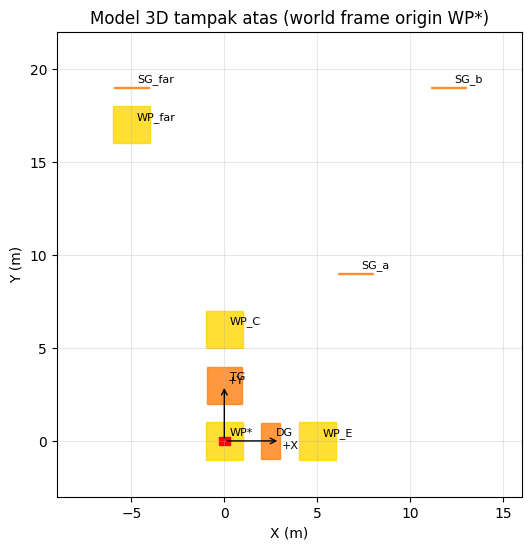

In [27]:
def draw_plan_topdown(ax, plan):
    "Tapak semua objek pada world frame (tampak atas)."
    for oid, r in plan.iterrows():
        if r.jenis == "waypoint":
            w, d = 2.0, 2.0
        elif r.jenis == "double":
            w, d = DG_DEPTH * MM, GATE_W * MM          # DG: bukaan menghadap +X
        elif r.jenis == "triple":
            w, d = GATE_W * MM, TG_DEPTH * MM
        else:
            w, d = GATE_W * MM, 0.08
        color = {"waypoint": "gold", "single": "tab:orange", "double": "tab:orange", "triple": "tab:orange"}[r.jenis]
        ax.add_patch(plt.Rectangle((r.X - w / 2, r.Y - d / 2), w, d, color=color, alpha=0.8))
        ax.annotate(oid, (r.X, r.Y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.add_patch(plt.Rectangle((-0.31, -0.2075), 0.62, 0.415, color="red"))
    ax.annotate("", xy=(3, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k"))
    ax.annotate("", xy=(0, 3), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k"))
    ax.text(3.1, -0.4, "+X", fontsize=8); ax.text(0.2, 3.1, "+Y", fontsize=8)
    ax.set_aspect("equal"); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)"); ax.grid(alpha=0.3)


fig, ax = plt.subplots(figsize=(6, 7))
draw_plan_topdown(ax, plan)

ax.set_xlim(-9, 16)
ax.set_ylim(-3, 22)
ax.set_title("Model 3D tampak atas (world frame origin WP*)")

plt.show()

## 5. Parameter Intrinsik Kamera

Panjang fokus dalam piksel diturunkan dari EXIF. Perlu diperiksa kembali karena gambar memiliki rasio **16:9 ($4080 \times 2296$)**, hasil *autocrop* dari gambar *raw* sensor **4:3**.

1. `FocalLength` = 5.5 mm dan `FocalLengthIn35mmFilm` = 23 mm, maka *crop factor* $\frac{23}{5.5} = 4.18$, sehingga diagonal sensor $= \frac{43.27}{4.18} = 10.35$ mm. Nilai sesuai dengan sensor 1/1.56" pada kamera utama Galaxy A55.
2. Diagonal tersebut berupa **4:3**, sehingga lebar sensor $= 0.8 \times 10.35 = 8.28$ mm, dan lebar itu terpetakan ke 4080 piksel karena *crop* ke 16:9 hanya memotong atas-bawah gambar.
3. $$f_{px} = f_{35} \cdot \frac{W_{px}}{0.8 \times 43.27} = 23 \cdot \frac{4080}{34.62} \approx 2711 \text{ px}.$$

Sebagai pembanding, pitch piksel sensor 50 MP adalah 1.0 µm (2.0 µm setelah *binning* $2 \times 2$ ke 12.5 MP), yang memberi $\frac{5.5}{0.002} = 2750$ px. 

`Orientation = 6` pada EXIF (*right-top*) menunjukkan bahwa piksel tersimpan secara *landscape* dan harus diputar $90^\circ$. `cv2.imread` sudah menerapkan orientasi ini, sehingga semua koordinat piksel di notebook ini berada pada gambar portrait $2296 \times 4080$ px. $f$ tidak berubah oleh rotasi, dan *principal point* diasumsikan di tengah gambar (A7).

Didapatkan parameter intrinsik kamera sebagai berikut.

In [28]:
raw = Image.open(IMAGE_PATH)
exif = {ExifTags.TAGS.get(k, k): v for k, v in raw.getexif().items()}
exif.update({ExifTags.TAGS.get(k, k): v for k, v in raw.getexif().get_ifd(0x8769).items()})
for k in ["Make", "Model", "Orientation", "FocalLength", "FocalLengthIn35mmFilm", "DigitalZoomRatio",
          "ExifImageWidth", "ExifImageHeight"]:
    print(f"{k:24s} {exif.get(k)}")
assert float(exif["DigitalZoomRatio"]) == 1.0, "zoom digital => gambar ter-crop, f harus dikoreksi"

IMG = cv2.imread(str(IMAGE_PATH))
IMG_RGB = cv2.cvtColor(IMG, cv2.COLOR_BGR2RGB)
IMG_H, IMG_W = IMG.shape[:2]
SENSOR_LONG_PX = max(int(exif["ExifImageWidth"]), int(exif["ExifImageHeight"]))

F35 = float(exif["FocalLengthIn35mmFilm"])
F_PX = F35 * SENSOR_LONG_PX / (0.8 * 43.27)
F_REL_SIGMA = 0.02
K = np.array([[F_PX, 0, IMG_W / 2], [0, F_PX, IMG_H / 2], [0, 0, 1.0]])
DIST = np.zeros(5)
print(f"\nGambar {IMG_W}x{IMG_H} (portrait), f = {F_PX:.1f} px, "
      f"HFOV = {2 * math.degrees(math.atan(IMG_W / 2 / F_PX)):.1f} deg, VFOV = {2 * math.degrees(math.atan(IMG_H / 2 / F_PX)):.1f} deg")
K

Make                     samsung
Model                    Galaxy A55 5G
Orientation              6
FocalLength              5.54
FocalLengthIn35mmFilm    23
DigitalZoomRatio         1.0
ExifImageWidth           4080
ExifImageHeight          2296

Gambar 2296x4080 (portrait), f = 2710.9 px, HFOV = 45.9 deg, VFOV = 73.9 deg


array([[2710.8851,    0.    , 1148.    ],
       [   0.    , 2710.8851, 2040.    ],
       [   0.    ,    0.    ,    1.    ]])

## 6. Perolehan Koordinat 2D

Objek target kecil di foto dengan kontras beragam: depan *gate* terkena bayangan, panel samping yang terkena matahari, latar rumput, gedung, dan langit. Pendekatan yang dipakai menggunakan teknik *hybrid*, dimana titik awal (*seed*) kasar diberikan, lalu algoritma memperhalus lokasinya hingga subpiksel secara terukur dan dapat diulang.

| Tahap | Algoritma | Tujuan |
|---|---|---|
| 1 | HSV Segmentation, Morph (*opening/closing*), Connected components | Menemukan dan membatasi ROI tiap objek oranye/kuning/merah secara otomatis |
| 2 | Melabeli titik per sudut (~ 2-3 px) dan definisi poligon tiap muka objek | memberi identitas (nama) pada setiap sudut, yaitu korespondensi |
| 3 | Caliper 1D: sampel profil warna (CIE-Lab, bilinear) tegak lurus tiap sisi poligon, cari puncak color gradient magnitude, lalu hyperbole interpolation untuk posisi subpiksel | titik-titik tepi subpiksel |
| 4 | Robust line fitting (M-estimator Huber, `cv2.fitLine`) per sisi | garis tepi menahan *outlier* (bayangan, oklusi) |
| 5 | 2-line intersectin tepi yang bertemu di suatu sudut | koordinat sudut subpiksel dengan ukuran kualitas (RMS di tepi) |

Sudut sebagai interseksi garis lebih akurat daripada detektor titik (Harris/Shi-Tomasi), karena puluhan titik tepi sepanjang sisi dirata-ratakan. Cara ini juga tetap bekerja di sudut tempat tiga permukaan bertemu karena muka teduh, panel terang, dan latar.

### 6.1 Deteksi ROI dengan segmentasi warna

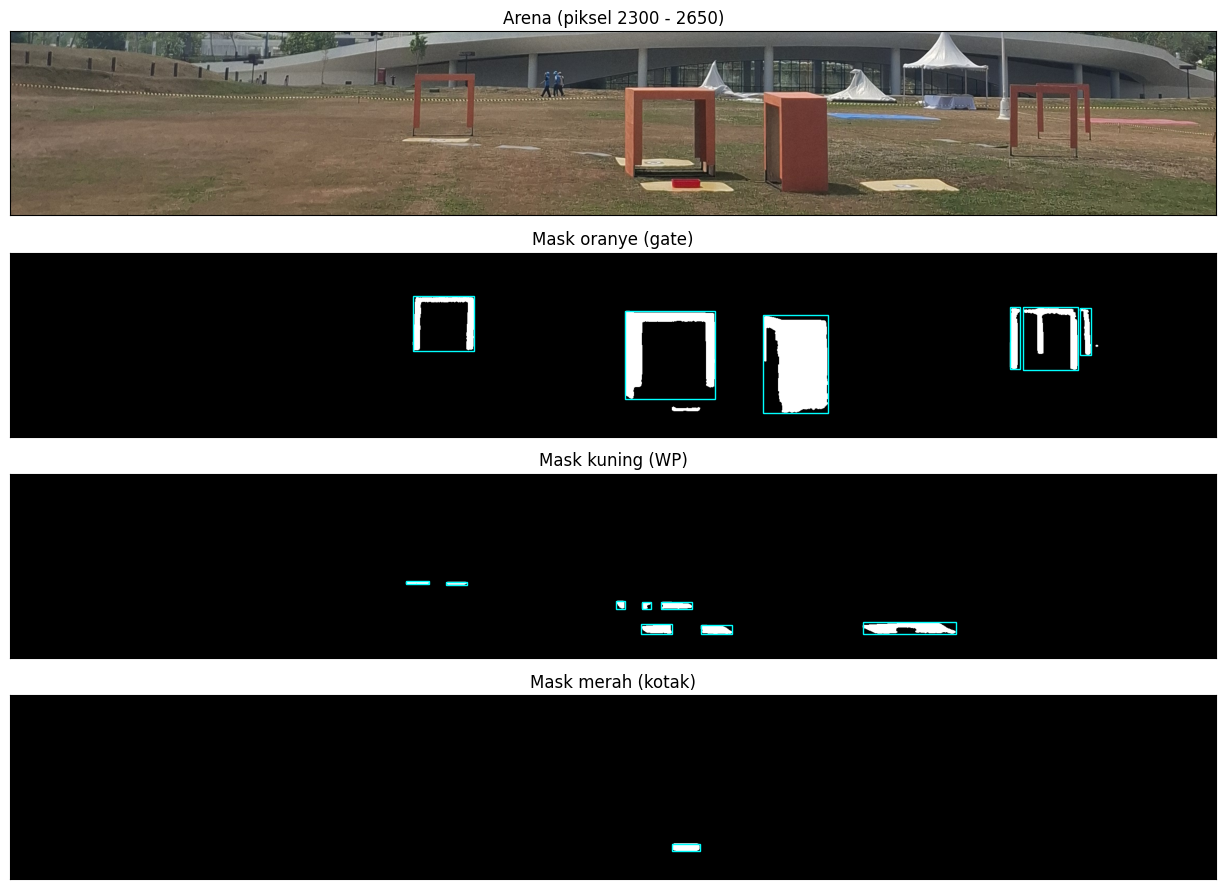

,kelas,u0,v0,lebar,tinggi,luas_px
6,kuning (WP),753,2504,44,6,251
7,kuning (WP),830,2505,39,6,222
8,kuning (WP),1153,2541,16,15,185
12,kuning (WP),1201,2586,58,18,833
10,kuning (WP),1202,2544,17,13,159
9,kuning (WP),1239,2543,59,14,645
13,kuning (WP),1314,2587,60,18,835
11,kuning (WP),1622,2582,177,22,2618
14,merah (kotak),1260,2582,52,15,747
0,oranye (gate),766,2383,117,103,3408


In [46]:
BAND = (2300, 2650)
HSV_CLASSES = {
    "oranye (gate)": [((0, 95, 85), (12, 255, 255))],
    "kuning (WP)":   [((16, 40, 180), (32, 140, 255))],
    "merah (kotak)": [((168, 120, 60), (180, 255, 255)), ((0, 160, 60), (3, 255, 255))],
}


def colour_mask(hsv, ranges, k=5):
    m = np.zeros(hsv.shape[:2], np.uint8)
    for lo, hi in ranges:
        m |= cv2.inRange(hsv, np.array(lo), np.array(hi))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel)
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, kernel)


hsv_band = cv2.cvtColor(IMG[BAND[0]:BAND[1]], cv2.COLOR_BGR2HSV)
fig, axes = plt.subplots(len(HSV_CLASSES) + 1, 1, figsize=(14, 9))
axes[0].imshow(IMG_RGB[BAND[0]:BAND[1]]); axes[0].set_title("Arena (piksel 2300 - 2650)")
blobs = []
for ax, (name, ranges) in zip(axes[1:], HSV_CLASSES.items()):
    m = colour_mask(hsv_band, ranges)
    n, lab, stats, cent = cv2.connectedComponentsWithStats(m)
    ax.imshow(m, cmap="gray"); ax.set_title(f"Mask {name}")
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if area < 150 or h < 6 or (name.startswith("oranye") and h < 40):
            continue
        blobs.append((name, x, y + BAND[0], w, h, area))
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="cyan", lw=1))
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
pd.DataFrame(blobs, columns=["kelas", "u0", "v0", "lebar", "tinggi", "luas_px"]).sort_values(["kelas", "u0"])

Identifikasi objek dari urutan kiri ke kanan pada foto (dicocokkan dengan model pada Bagian 4):

| ROI (u ~) | Objek | Alasan |
|---|---|---|
| 770-885 | SG_far | rangka datar paling kiri, WP_far di depannya |
| 1170-1340 | TG | kotak dengan bukaan menghadap kamera; WP\* + kotak merah tepat di depannya |
| 1433-1553 | DG | kotak dilihat dari samping (bukaannya menghadap -X), kedalaman ~ 1 m |
| 1610-1800 | WP_E | WP di kanan DG |
| 1900-2030 | SG_a | SG kanan yang lebih besar (lebih dekat) |
| 1950-2056 | SG_b | SG kanan yang lebih kecil, sebagian tertutup SG_a |

### 6.2 Caliper, *robust line fitting*, dan intersection

In [47]:
LAB = cv2.GaussianBlur(cv2.cvtColor(IMG, cv2.COLOR_BGR2LAB).astype(np.float32), (0, 0), 0.8)


def sample_bilinear(img, xy):
    xy = np.asarray(xy, np.float32).reshape(1, -1, 2)
    return cv2.remap(img, xy[..., 0], xy[..., 1], cv2.INTER_LINEAR).reshape(-1, img.shape[2])


def caliper_edge(a, b, ranges=((0.15, 0.85),), half=4.0, step=0.25, density=25):
    "Cari tepi antara seed a dan b: cek profil tegak lurus, puncak gradien Lab, parabola, lalu Huber line fit."
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = (b - a) / np.linalg.norm(b - a)
    nrm = np.array([-d[1], d[0]])
    ts = np.concatenate([np.linspace(t0, t1, max(3, int(density * (t1 - t0) / 0.7))) for t0, t1 in ranges])
    offs = np.arange(-half, half + 1e-9, step)
    base = a + ts[:, None] * (b - a)
    grid = base[:, None, :] + offs[None, :, None] * nrm
    prof = sample_bilinear(LAB, grid.reshape(-1, 2)).reshape(len(ts), len(offs), 3)
    grad = np.linalg.norm(np.gradient(prof, step, axis=1), axis=2)
    pts, strength = [], []
    for i in range(len(ts)):
        k = int(np.argmax(grad[i, 1:-1])) + 1
        g0, g1, g2 = grad[i, k - 1:k + 2]
        den = g0 - 2 * g1 + g2
        sub = 0.5 * (g0 - g2) / den if abs(den) > 1e-9 else 0.0
        pts.append(base[i] + (offs[k] + sub * step) * nrm)
        strength.append(g1)
    pts, strength = np.array(pts), np.array(strength)
    keep = strength > 0.35 * np.median(strength)
    vx, vy, x0, y0 = cv2.fitLine(pts[keep].astype(np.float32), cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
    p0, v = np.array([x0, y0]), np.array([vx, vy])
    resid = (pts[keep] - p0) @ np.array([-v[1], v[0]])
    return {"p0": p0, "v": v, "pts": pts, "keep": keep, "rms": float(np.sqrt(np.mean(resid ** 2)))}


def intersect_lines(e1, e2):
    A = np.array([e1["v"], -e2["v"]]).T
    if abs(np.linalg.det(A)) < 0.2:
        return None
    s = np.linalg.solve(A, e2["p0"] - e1["p0"])
    return e1["p0"] + s[0] * e1["v"]


def refine_polygon(seeds, order, use, edge_opts=None):
    edge_opts = edge_opts or {}
    edges = {}
    for i, a in enumerate(order):
        b = order[(i + 1) % len(order)]
        opt = edge_opts.get((a, b), {})
        if opt is not None:
            edges[(a, b)] = caliper_edge(seeds[a], seeds[b], **opt)
    out = {}
    for i, v in enumerate(order):
        if v not in use:
            continue
        e_in, e_out = edges.get((order[i - 1], v)), edges.get((v, order[(i + 1) % len(order)]))
        p = intersect_lines(e_in, e_out)
        out[v] = (p, float(np.linalg.norm(p - seeds[v])), max(e_in["rms"], e_out["rms"]))
    return out, edges

Keterangan: *Seed* dibaca dari crop yang diperbesar 12-16 kali, dengan ketelitian sekitar 2-3 px. Setiap muka objek ditulis sebagai poligon tertutup. Sisi yang tidak terlihat atau tertutup diberi `None`, dan sisi yang sebagian tertutup diberi rentang parameter `ranges` (0 = sudut awal, 1 = sudut akhir) agar caliper hanya mencari pada bagian yang terlihat.

In [48]:
FRAME = ["oBL", "oTL", "oTR", "oBR", "iBR", "iTR", "iTL", "iBL"]   # urutan keliling rangka muka

OBJECTS = {
    # muka TG yang menghadap kamera (teduh)
    "TG": [dict(seeds={"oTL": (1187, 2414), "oTR": (1340, 2413.5), "iTL": (1203, 2430), "iTR": (1323.5, 2430),
                       "oBL": (1187, 2555), "iBL": (1202, 2555), "oBR": (1340.3, 2555), "iBR": (1325, 2555)},
                order=FRAME, use=FRAME),
           # siluet atas + panel samping kiri TG (terang): pojok atas-belakang-kiri
           dict(seeds={"sB": (1170.5, 2560), "bTL": (1170.5, 2408), "bTR": (1338, 2407.5)},
                order=["sB", "bTL", "bTR"], use=["bTL"],
                opts={("bTR", "sB"): None, ("bTL", "bTR"): dict(ranges=((0.05, 0.6),))})],
    "DG": [dict(seeds={"nBL": (1467, 2600), "nTL": (1467, 2427.5), "nTR": (1553, 2428), "nBR": (1553, 2600)},
                order=["nBL", "nTL", "nTR", "nBR"], use=["nTL", "nTR"], opts={("nBR", "nBL"): None}),
           # bukaan gelap pada muka -X DG; rangka jauhnya hanya ~4 px sehingga jendela caliper dipersempit
           dict(seeds={"fiT": (1438, 2435), "niT": (1463, 2444), "niB": (1463.5, 2579), "fiB": (1438, 2563)},
                order=["fiT", "niT", "niB", "fiB"], use=["fiT", "niT"],
                opts={("niB", "fiB"): None, ("fiB", "fiT"): dict(half=1.5), ("niT", "niB"): dict(half=2.0)}),
           dict(seeds={"fB": (1434, 2563), "fT": (1434, 2416), "tR": (1553, 2421)},
                order=["fB", "fT", "tR"], use=["fT"],
                opts={("tR", "fB"): None, ("fB", "fT"): dict(half=1.5), ("fT", "tR"): dict(ranges=((0.05, 0.4),))})],
    "WP*": [dict(seeds={"FL": (1198.3, 2588.5), "FR": (1355, 2588.3), "NR": (1376.7, 2602), "NL": (1210.8, 2602)},
                 order=["FL", "FR", "NR", "NL"], use=["FL", "FR", "NR", "NL"],
                 opts={("FL", "FR"): dict(ranges=((0.05, 0.35), (0.76, 0.95)))})],       # tertutup kotak merah
    "RB": [dict(seeds={"BL": (1259, 2597.8), "TL": (1258.6, 2581), "TR": (1311.4, 2581), "BR": (1311, 2597.8)},
                order=["BL", "TL", "TR", "BR"], use=["BL", "TL", "TR", "BR"], opts={("TL", "TR"): dict(half=2.0)})],
    "WP_E": [dict(seeds={"FL": (1615.5, 2587.5), "FR": (1765, 2581.5), "NR": (1782, 2595.5), "NL": (1648, 2603)},
                  order=["FL", "FR", "NR", "NL"], use=["FL", "FR", "NR", "NL"])],
    "SG_far": [dict(seeds={"oTL": (770.3, 2381.1), "oTR": (884.5, 2381), "iTL": (782, 2394.5), "iTR": (871.3, 2394),
                           "oBL": (768.5, 2484), "iBL": (779, 2484), "oBR": (881, 2483), "iBR": (869, 2483)},
                    order=FRAME, use=FRAME)],
    "SG_a": [dict(seeds={"oTL": (1902.5, 2401.5), "oTR": (2030.5, 2405), "iTL": (1918, 2416), "iTR": (2016, 2417),
                         "oBL": (1902, 2520.5), "iBL": (1916, 2520.5), "oBR": (2030, 2521.5), "iBR": (2017, 2521.5)},
                  order=FRAME, use=FRAME,
                  opts={("oTL", "oTR"): dict(ranges=((0.05, 0.35),)),
                        ("iTR", "iTL"): dict(ranges=((0.1, 0.45), (0.7, 0.9)))})],
    "SG_b": [dict(seeds={"oTL": (1951.5, 2400.5), "oTR": (2052, 2401), "iTL": (1966, 2412), "iTR": (2041.3, 2412),
                         "oBL": (1953.7, 2491), "iBL": (1965.8, 2491), "oBR": (2055.4, 2493), "iBR": (2045.8, 2493)},
                  order=FRAME, use=["oTR", "oBR", "iBR", "iBL", "oBL"],                  # sisanya tertutup SG_a
                  opts={("oBL", "oTL"): dict(ranges=((0.05, 0.75),)), ("oTL", "oTR"): dict(ranges=((0.8, 0.95),)),
                        ("iTR", "iTL"): None})],
}

rows, ALL_EDGES = [], []
for obj, faces in OBJECTS.items():
    for face in faces:
        seeds = {k: np.array(v, float) for k, v in face["seeds"].items()}
        out, edges = refine_polygon(seeds, face["order"], face["use"], face.get("opts"))
        ALL_EDGES += list(edges.values())
        for name, (p, moved, rms) in out.items():
            rows.append((f"{obj}_{name}", obj, p[0], p[1], moved, rms))

obs = pd.DataFrame(rows, columns=["id", "objek", "u", "v", "geser_dari_seed_px", "rms_tepi_px"]).set_index("id")
obs["sigma_px"] = obs.rms_tepi_px.clip(lower=0.5)
obs

,objek,u,v,geser_dari_seed_px,rms_tepi_px,sigma_px
id,,,,,,
TG_oBL,TG,1185.242,2554.660,1.791,0.295,0.500
TG_oTL,TG,1185.834,2412.494,1.904,0.295,0.500
TG_oTR,TG,1340.917,2412.489,1.365,0.438,0.500
TG_oBR,TG,1341.898,2555.483,1.669,0.758,0.758
TG_iBR,TG,1324.726,2554.217,0.829,0.758,0.758
TG_iTR,TG,1323.086,2430.283,0.502,1.719,1.719
TG_iTL,TG,1202.446,2429.791,0.592,1.719,1.719
TG_iBL,TG,1202.536,2554.509,0.727,0.101,0.500
TG_bTL,TG,1169.434,2407.888,1.072,0.542,0.542


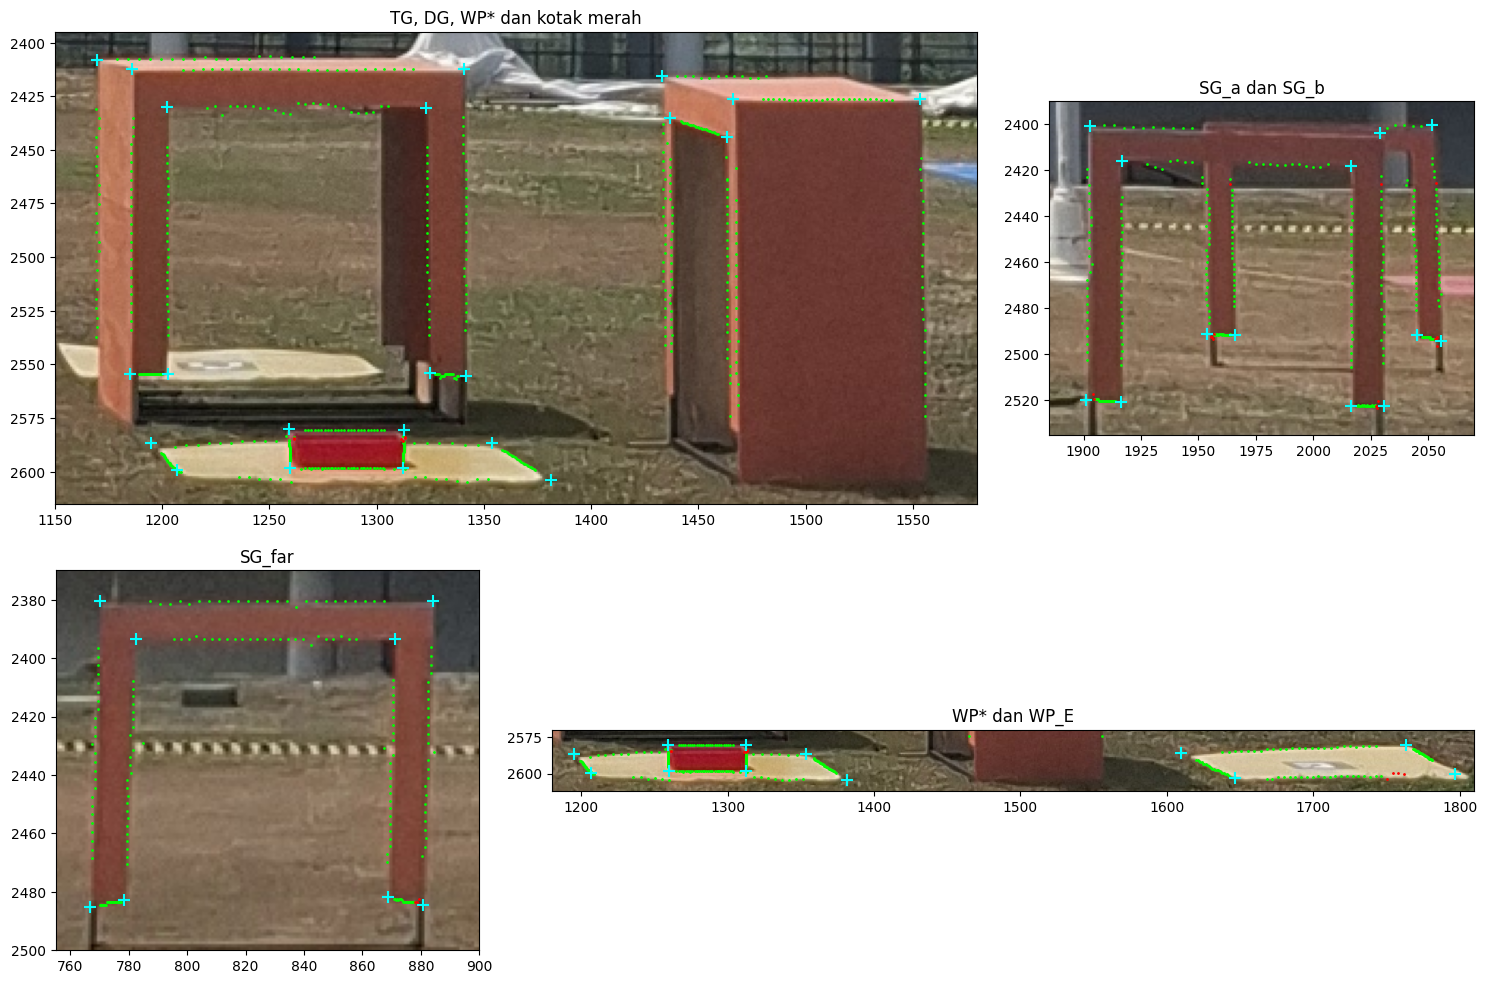

In [49]:
def show_extraction(ax, box, title):
    u0, v0, u1, v1 = box
    ax.imshow(IMG_RGB[v0:v1, u0:u1], extent=(u0, u1, v1, v0))
    for e in ALL_EDGES:
        p = e["pts"]
        ax.plot(p[e["keep"], 0], p[e["keep"], 1], ".", ms=2, color="lime")
        ax.plot(p[~e["keep"], 0], p[~e["keep"], 1], ".", ms=2, color="red")
    sel = obs[(obs.u > u0) & (obs.u < u1) & (obs.v > v0) & (obs.v < v1)]
    ax.plot(sel.u.to_numpy(), sel.v.to_numpy(), "+", color="cyan", ms=9, mew=1.5)
    ax.set_xlim(u0, u1); ax.set_ylim(v1, v0); ax.set_title(title)


fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.3, 1])
show_extraction(fig.add_subplot(gs[0, :2]), (1150, 2395, 1580, 2615), "TG, DG, WP* dan kotak merah")
show_extraction(fig.add_subplot(gs[0, 2]), (1885, 2390, 2070, 2535), "SG_a dan SG_b")
show_extraction(fig.add_subplot(gs[1, 0]), (755, 2370, 900, 2500), "SG_far")
show_extraction(fig.add_subplot(gs[1, 1:]), (1180, 2570, 1810, 2612), "WP* dan WP_E")
plt.tight_layout(); plt.show()

Keterangan: titik hijau adalah titik tepi subpiksel hasil caliper yang dipakai pada line fit, titik merah adalah profil yang ditolak, dan tanda `+` biru adalah sudut hasil intersection.

**Hasil dan kualitas:**
- Sudut *gate* bergeser 0.4-2 px dari *seed*, dan RMS tepinya umumnya < 1 px. 
- RMS tepi atas-dalam TG lebih tinggi (~ 1,6 px) karena di balik bukaannya terlihat rangka belakang dan sisi bawah panel atas, sehingga ada dua tepi sejajar yang berdekatan. Deviasi titik tersebut ikut membesar.
- Sudut WP yang jauh terlihat rupanya lebih buruk: tebal WP di gambar hanya 13-16 px, sisi pendeknya membulat dan kabur, dan sudut `WP_E_NR` meleset belasan piksel.

## 7. Korespondensi 2D-3D

Korespondensi dibuat berdasarkan nama yang sudah didefinisikan sebelumnya. Titik dibagi menurut perannya:

- **`pose`:** area dekat yang posisinya relatif terhadap WP\* hanya dipisah sekitar ~1 m pada denah. Titik-titik ini non-koplanar (tersebar di $X$ 2.9 m, $Y$ 5 m, $Z$ 1.7 m).
- **`holdout`:** sama sekali tidak dipakai saat *solve*.
- **`analisis`:** *gate* jauh.

In [50]:
corr = model.join(obs.drop(columns="objek"), how="inner")
print(corr.groupby("peran").size().rename("jumlah korespondensi").to_string())
POSE_IDS = corr.index[corr.peran == "pose"].tolist()
HOLD_IDS = corr.index[corr.peran == "holdout"].tolist()
corr.loc[POSE_IDS, ["X", "Y", "Z", "u", "v", "sigma_px"]]

peran
analisis    21
holdout     12
pose        14


,X,Y,Z,u,v,sigma_px
id,,,,,,
TG_oTL,-0.950,2.00,2.0,1185.834,2412.494,0.500
TG_oTR,0.950,2.00,2.0,1340.917,2412.489,0.500
TG_iTL,-0.750,2.00,1.8,1202.446,2429.791,1.719
TG_iTR,0.750,2.00,1.8,1323.086,2430.283,1.719
TG_oBL,-0.950,2.00,0.3,1185.242,2554.660,0.500
TG_iBL,-0.750,2.00,0.3,1202.536,2554.509,0.500
TG_oBR,0.950,2.00,0.3,1341.898,2555.483,0.758
TG_iBR,0.750,2.00,0.3,1324.726,2554.217,0.758
TG_bTL,-0.950,4.00,2.0,1169.434,2407.888,0.542


## 8. Estimasi Posisi dan Orientasi Kamera

### 8.1 Algoritma

$$\min_{R,\,t}\ \sum_i \big\| x_i - \pi\big(K(RX_i + t)\big) \big\|^2$$

1. **Solusi awal** dengan tiga solver berbeda:
   - **SQPnP**: global-optimal untuk konfigurasi titik umum, termasuk planar maupun non-planar.
   - **EPnP**: solusi tertutup dari 4 titik kontrol virtual.
   - **Iteratif**: DLT/homografi lalu Levenberg–Marquardt.
2. **Penyempurnaan** dengan Levenberg–Marquardt (`solvePnPRefineLM`) pada error reproyeksi.
3. **Pemeriksaan:** ketiga solver harus konvergen ke pose yang sama setelah penyempurnaan. Kamera juga harus berada di atas tanah dan semua titik di depan kamera.
4. **RANSAC** dijalankan sebagai pemeriksaan *outlier* (ambang 4 px).

In [51]:
SOLVERS = {"SQPnP": cv2.SOLVEPNP_SQPNP, "EPnP": cv2.SOLVEPNP_EPNP, "Iteratif": cv2.SOLVEPNP_ITERATIVE}


def project(Xw, R, t, K, dist=DIST):
    rvec, _ = cv2.Rodrigues(R)
    uv, _ = cv2.projectPoints(np.asarray(Xw, float).reshape(-1, 3), rvec, np.asarray(t, float), K, dist)
    return uv.reshape(-1, 2)


def solve_pose(Xw, x, K, method="SQPnP"):
    Xw = np.ascontiguousarray(Xw, np.float64); x = np.ascontiguousarray(x, np.float64)
    ok, rvec, tvec = cv2.solvePnP(Xw, x, K, DIST, flags=SOLVERS[method])
    if not ok:
        return None
    rvec, tvec = cv2.solvePnPRefineLM(Xw, x, K, DIST, rvec, tvec)
    R, _ = cv2.Rodrigues(rvec)
    t = tvec.ravel()
    res = project(Xw, R, t, K) - x
    return {"R": R, "t": t, "res": res, "rms": float(np.sqrt(np.mean(np.sum(res ** 2, 1))))}


def describe(sol):
    C = camera_centre(sol["R"], sol["t"])
    h, p, r = angles_from_rot(sol["R"])
    return {"X": C[0], "Y": C[1], "Z": C[2], "heading": h, "pitch": p, "roll": r, "rms_px": sol["rms"]}


Xp = corr.loc[POSE_IDS, ["X", "Y", "Z"]].to_numpy(float)
xp = corr.loc[POSE_IDS, ["u", "v"]].to_numpy(float)

solver_table = []
for name in SOLVERS:
    s = solve_pose(Xp, xp, K, name)
    depth = (s["R"] @ Xp.T + s["t"][:, None])[2]
    solver_table.append({"solver": name, **describe(s), "di depan kamera": bool((depth > 0).all())})
solver_table = pd.DataFrame(solver_table).set_index("solver")

ok, rv_r, tv_r, inl = cv2.solvePnPRansac(Xp, xp, K, DIST, flags=cv2.SOLVEPNP_SQPNP, reprojectionError=4.0,
                                         iterationsCount=1000, confidence=0.999)
print(f"RANSAC (4 px): {len(inl)}/{len(Xp)} inlier; outlier: {sorted(set(POSE_IDS) - {POSE_IDS[i] for i in inl.ravel()}) or 'tidak ada'}")
solver_table

RANSAC (4 px): 13/14 inlier; outlier: ['TG_bTL']


,X,Y,Z,heading,pitch,roll,rms_px,di depan kamera
solver,,,,,,,,
SQPnP,-3.687,-31.532,3.766,3.93,4.873,0.277,2.268,True
EPnP,-3.687,-31.532,3.766,3.93,4.873,0.277,2.268,True
Iteratif,-3.687,-31.532,3.766,3.93,4.873,0.277,2.268,True


Ketiga solver konvergen ke pose yang identik setelah penyempurnaan LM, sehingga tidak ada ambiguitas solusi. Kamera berada di atas tanah dan semua titik berada di depannya. RANSAC dengan ambang 4 px hanya menolak `TG_bTL`. Uji leave-one-out pada bagian 9 menunjukkan bahwa membuang titik itu hanya menggeser posisi 0.30 m, jauh di bawah ketidakpastian total, jadi ke-14 titik tetap dipakai.

In [52]:
best = solve_pose(Xp, xp, K, "SQPnP")
R_CW, T_CW = best["R"], best["t"]
C_W = camera_centre(R_CW, T_CW)
HEADING, PITCH, ROLL = angles_from_rot(R_CW)
pose = describe(best)

print("R (world -> camera) =\n", R_CW)
print("t =", T_CW)
print(f"\nPosisi kamera  C = ({C_W[0]:.2f}, {C_W[1]:.2f}, {C_W[2]:.2f}) m   (relatif terhadap pusat WP*)")
print(f"Jarak horizontal ke origin = {np.hypot(*C_W[:2]):.2f} m, jarak 3D = {np.linalg.norm(C_W):.2f} m")
print(f"Heading = {HEADING:.2f} deg, Pitch = {PITCH:.2f} deg, Roll = {ROLL:.2f} deg")
print(f"RMS reproyeksi = {best['rms']:.2f} px pada {len(Xp)} titik")

R (world -> camera) =
 [[ 0.9977 -0.0681 -0.0048]
 [ 0.001   0.0851 -0.9964]
 [ 0.0683  0.994   0.0849]]
t = [ 1.5481  6.4381 31.2762]

Posisi kamera  C = (-3.69, -31.53, 3.77) m   (relatif terhadap pusat WP*)
Jarak horizontal ke origin = 31.75 m, jarak 3D = 31.97 m
Heading = 3.93 deg, Pitch = 4.87 deg, Roll = 0.28 deg
RMS reproyeksi = 2.27 px pada 14 titik


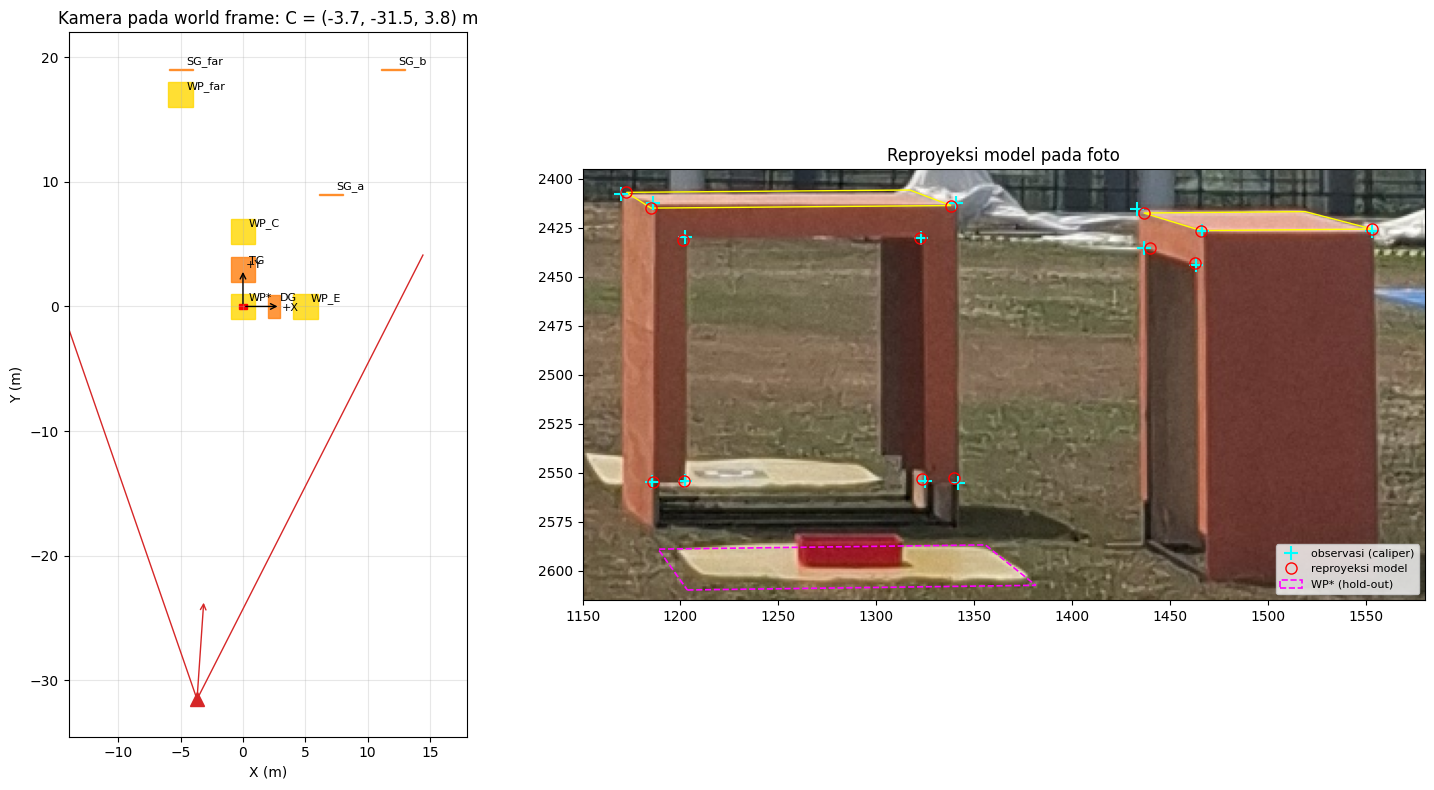

In [63]:
def draw_camera(ax, R, t, length=40, **kw):
    C = camera_centre(R, t)
    for u in (0, IMG_W):
        ray = R.T @ np.linalg.inv(K) @ np.array([u, IMG_H / 2, 1.0])
        ray = ray[:2] / np.linalg.norm(ray[:2])
        ax.plot(*np.c_[C[:2], C[:2] + length * ray], **kw)
    fwd = R[2, :2] / np.linalg.norm(R[2, :2])
    ax.annotate("", xy=C[:2] + 8 * fwd, xytext=C[:2], arrowprops=dict(arrowstyle="->", color=kw.get("color", "k")))
    ax.plot(*C[:2], "^", ms=10, color=kw.get("color", "k"))


fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1, 1.4]})
draw_plan_topdown(a1, plan)
draw_camera(a1, R_CW, T_CW, color="tab:red", lw=1)
a1.set_xlim(-14, 18); a1.set_ylim(C_W[1] - 3, 22)
a1.set_title(f"Kamera pada world frame: C = ({C_W[0]:.1f}, {C_W[1]:.1f}, {C_W[2]:.1f}) m")

box = (1150, 2395, 1580, 2615)
a2.imshow(IMG_RGB[box[1]:box[3], box[0]:box[2]], extent=(box[0], box[2], box[3], box[1]))
a2.plot(xp[:, 0], xp[:, 1], "+", color="cyan", ms=10, mew=1.5, label="observasi (caliper)")
rp = project(Xp, R_CW, T_CW, K)
a2.plot(rp[:, 0], rp[:, 1], "o", mfc="none", mec="red", ms=8, label="reproyeksi model")
for oid in ["TG", "DG"]:
    r = plan.loc[oid]
    w, d = (GATE_W * MM, TG_DEPTH * MM) if oid == "TG" else (DG_DEPTH * MM, GATE_W * MM)
    base = np.array([[r.X - w / 2, r.Y - d / 2], [r.X + w / 2, r.Y - d / 2], [r.X + w / 2, r.Y + d / 2], [r.X - w / 2, r.Y + d / 2]])
    top = project(np.c_[base, np.full(4, Z_TOP)], R_CW, T_CW, K)
    a2.add_patch(MplPolygon(top, fill=False, ec="yellow", lw=1))
wp_proj = project(np.array([[-1, -1, 0], [1, -1, 0], [1, 1, 0], [-1, 1, 0]]), R_CW, T_CW, K)

a2.add_patch(MplPolygon(wp_proj, fill=False, ec="magenta", lw=1.2, ls="--", label="WP* (hold-out)"))
a2.set_xlim(box[0], box[2])
a2.set_ylim(box[3], box[1])
a2.legend(loc="lower right", fontsize=8)
a2.set_title("Reproyeksi model pada foto")

plt.tight_layout()
plt.show()

Keterangan:
* Kiri: posisi dan kerucut pandang kamera (merah) pada world frame. Kamera berdiri di luar arena, di belakang dan sedikit ke kiri WP\*, menghadap hampir lurus ke $+Y$. 
* Kanan: lingkaran merah (reproyeksi model) jatuh di atas tanda + biru (observasi). Garis kuning adalah tepi atas TG/DG menurut model, dan garis putus-putus magenta adalah WP\* menurut model, yang tidak ikut dipakai saat solve.

## 9. Validasi

### 9.1 Residual per titik

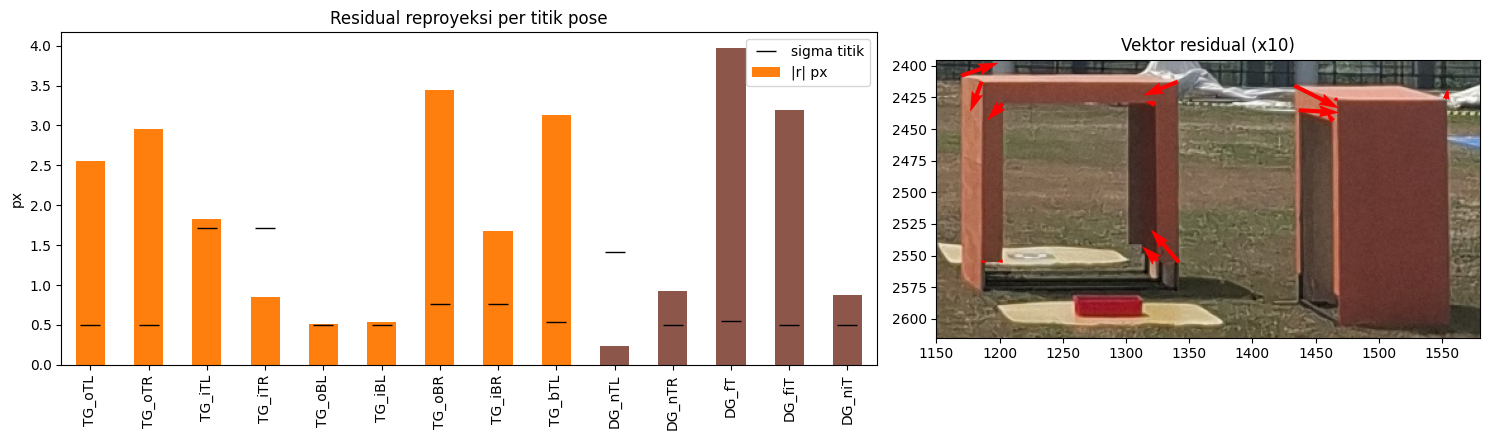

,TG_oTL,TG_oTR,TG_iTL,TG_iTR,TG_oBL,TG_iBL,TG_oBR,TG_iBR,TG_bTL,DG_nTL,DG_nTR,DG_fT,DG_fiT,DG_niT
du,-0.92,-2.75,-1.24,-0.82,0.50,-0.53,-2.24,-1.21,2.96,-0.19,0.16,3.54,3.19,-0.46
dv,2.39,1.10,1.34,-0.23,0.06,0.01,-2.61,-1.15,-1.04,-0.14,-0.91,1.79,0.19,-0.74
|r| px,2.56,2.96,1.82,0.86,0.51,0.53,3.44,1.67,3.14,0.24,0.92,3.97,3.20,0.87
sigma_px,0.50,0.50,1.72,1.72,0.50,0.50,0.76,0.76,0.54,1.41,0.50,0.54,0.50,0.50


In [54]:
res = pd.DataFrame(best["res"], index=POSE_IDS, columns=["du", "dv"])
res["|r| px"] = np.hypot(res.du, res.dv)
res["sigma_px"] = corr.loc[POSE_IDS, "sigma_px"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
res["|r| px"].plot.bar(ax=a1, color=["tab:orange" if i.startswith("TG") else "tab:brown" for i in res.index])
a1.plot(np.arange(len(res)), res.sigma_px.to_numpy(), "k_", ms=14, label="sigma titik")
a1.set_ylabel("px"); a1.set_title("Residual reproyeksi per titik pose"); a1.legend()
a2.imshow(IMG_RGB[2395:2615, 1150:1580], extent=(1150, 1580, 2615, 2395))
a2.quiver(xp[:, 0], xp[:, 1], res.du.to_numpy() * 10, res.dv.to_numpy() * 10, color="red", angles="xy", scale_units="xy", scale=1)
a2.set_title("Vektor residual (x10)")
plt.tight_layout(); plt.show()
res.round(2).T

Interpretasi: RMS 2.3 px lebih besar daripada $\sigma$ titik (0,5-1,6 px), dan residualnya tidak acak. Sudut kanan TG (`oTR`, `oBR`) tertarik ke kiri, sedangkan titik-titik DG di muka -X (`fT`, `fiT`) tertarik ke kanan. Pola tarik-menarik ini menandakan bahwa posisi DG relatif terhadap TG di lapangan berbeda beberapa puluh sentimeter dari denah (A6).

### 9.2 Titik *hold-out* (WP\*, kotak merah, WP_E)

Titik-titik ini tidak dipakai menghitung pose. Jika denah dan pose benar, reproyeksinya harus jatuh dekat observasi, dalam batas kualitas ekstraksinya masing masing. Uji ini paling penting untuk **origin**, karena origin didefinisikan pada WP\*, sedangkan pose dihitung dari TG/DG.

In [55]:
Xh = corr.loc[HOLD_IDS, ["X", "Y", "Z"]].to_numpy(float)
xh = corr.loc[HOLD_IDS, ["u", "v"]].to_numpy(float)
hold = pd.DataFrame(project(Xh, R_CW, T_CW, K) - xh, index=HOLD_IDS, columns=["du", "dv"])
hold["|r| px"] = np.hypot(hold.du, hold.dv)
hold["rms_tepi_px"] = corr.loc[HOLD_IDS, "rms_tepi_px"]
print(hold.groupby(corr.loc[HOLD_IDS, "objek"])["|r| px"].median().rename("median |r| (px)").round(2).to_string())


def offset_on_ground(ids):
    "Translasi (dX, dY) yang membuat objek hold-out paling pas, dengan pose tetap (Gauss-Newton)."
    X0 = corr.loc[ids, ["X", "Y", "Z"]].to_numpy(float); x = corr.loc[ids, ["u", "v"]].to_numpy(float)
    d = np.zeros(2)
    for _ in range(10):
        f = lambda dd: (project(X0 + np.r_[dd, 0], R_CW, T_CW, K) - x).ravel()
        J = np.stack([(f(d + e) - f(d - e)) / 2e-4 for e in np.eye(2) * 1e-4], 1)
        d += np.linalg.lstsq(J, -f(d), rcond=None)[0]
    return d


for objname in ["RB", "WP*"]:
    ids = [i for i in HOLD_IDS if corr.loc[i, "objek"] == objname]
    dX, dY = offset_on_ground(ids)
    print(f"{objname}: offset terbaik terhadap denah dX = {dX:+.2f} m, dY = {dY:+.2f} m")
hold.round(2)

objek
RB      4.86
WP*     5.06
WP_E    5.31
RB: offset terbaik terhadap denah dX = +0.07 m, dY = +0.22 m
WP*: offset terbaik terhadap denah dX = +0.08 m, dY = +0.46 m


,du,dv,|r| px,rms_tepi_px
WP*_FL,-6.23,2.50,6.71,0.86
WP*_FR,1.91,0.28,1.93,0.86
WP*_NR,0.05,3.42,3.42,2.59
WP*_NL,-3.29,10.58,11.08,2.59
RB_TL,-5.77,3.24,6.62,0.59
RB_TR,-6.32,2.37,6.75,0.12
RB_BL,-2.26,2.12,3.10,0.59
RB_BR,-1.16,1.41,1.83,0.07
WP_E_FL,-7.05,-2.35,7.43,0.34
WP_E_FR,2.86,1.38,3.18,0.34


Interpretasi: Kotak merah, yang paling tajam di antara objek *hold-out*, meleset sekitar 1.7-6.7 px, dan pergeseran terbaiknya hanya +0.07 m di $X$ dan +0.22 m di $Y$. WP\* bergeser (+0.07, +0.46) m, dengan catatan sudut WP kabur. Jadi, origin yang diturunkan dari denah dan pose yang dihitung dari TG-DG saling konsisten dalam rentang ~0.2-0.5 m. Nilai ini sesuai dengan toleransi penempatan (A6) dan ketidakpastian kedalaman pose. Residual besar `WP_E_NR` (~ 22 px) berasal dari kegagalan ekstraksi sudut tersebut pada bagian 6, bukan dari pose.

### 9.3 *Leave-one-out* dan kestabilan

In [56]:
loo = []
for oid in ["TG", "DG"]:
    keep = [i for i in POSE_IDS if not i.startswith(oid)]
    if len(keep) >= 6:
        s = solve_pose(corr.loc[keep, ["X", "Y", "Z"]].to_numpy(float), corr.loc[keep, ["u", "v"]].to_numpy(float), K)
        loo.append({"dibuang": oid, "n": len(keep), **describe(s)})
for pid in POSE_IDS:
    keep = [i for i in POSE_IDS if i != pid]
    s = solve_pose(corr.loc[keep, ["X", "Y", "Z"]].to_numpy(float), corr.loc[keep, ["u", "v"]].to_numpy(float), K)
    loo.append({"dibuang": pid, "n": len(keep), **describe(s)})
loo = pd.DataFrame(loo).set_index("dibuang")
loo["geser_posisi_m"] = np.linalg.norm(loo[["X", "Y", "Z"]].to_numpy() - C_W, axis=1)
loo.round(2)

,n,X,Y,Z,heading,pitch,roll,rms_px,geser_posisi_m
dibuang,,,,,,,,,
DG,9,-4.46,-31.02,3.02,5.24,6.08,-0.25,0.79,1.19
TG_oTL,13,-3.71,-31.52,3.85,4.00,4.75,0.47,2.21,0.09
TG_oTR,13,-3.81,-31.59,3.77,4.13,4.88,0.31,2.18,0.13
TG_iTL,13,-3.68,-31.50,3.81,3.93,4.80,0.38,2.29,0.05
TG_iTR,13,-3.71,-31.54,3.78,3.97,4.85,0.30,2.34,0.02
TG_oBL,13,-3.70,-31.55,3.78,3.96,4.85,0.31,2.35,0.03
TG_iBL,13,-3.67,-31.52,3.75,3.91,4.89,0.25,2.35,0.02
TG_oBR,13,-3.88,-31.64,3.80,4.23,4.82,0.26,2.10,0.22
TG_iBR,13,-3.77,-31.58,3.77,4.05,4.87,0.24,2.30,0.09


Membuang satu titik mana pun menggeser posisi paling jauh 0.3 m, sehingga tidak ada satu titik yang mendominasi solusi. Membuang seluruh DG menggeser posisi 1.1 m dan heading $1.1^\circ$. Area di dekat situ memang hanya terdiri atas dua objek, sehingga posisi relatif keduanya menjadi faktor penentu.

### 9.4 Independent test di garis polisi kuning-hitam batas arena

Pita garis polisi menandai batas arena. Baris piksel pita di kolom tengah gambar diukur otomatis dari mask kuning, lalu diproyeksikan balik ke bidang tanah $Z=0$ dengan pose hasil. Batas bawah lapangan pada denah berada di $Y = -11$ m (WP\* berjarak 11 m dari tepi bawah). Pemeriksaan ini lemah karena tidak diketahui apakah pita dipasang tepat di garis batas lapangan, apakah lurus/sejajar sumbu $X$, dan apakah tanah di depan kamera datar. Hasilnya diperlakukan sebagai uji kewajaran saja.

In [57]:
strip = cv2.cvtColor(IMG[2850:2950, IMG_W // 2 - 150:IMG_W // 2 + 150], cv2.COLOR_BGR2HSV)
yellow = cv2.inRange(strip, np.array((18, 80, 120)), np.array((35, 255, 255)))
rows_with_tape = np.where(yellow.mean(1) > 0.25 * yellow.mean(1).max())[0]
v_tape = 2850 + rows_with_tape.mean()
ray = R_CW.T @ np.linalg.inv(K) @ np.array([IMG_W / 2, v_tape, 1.0])
P_tape = C_W + (-C_W[2] / ray[2]) * ray
v_plan = project(np.array([[C_W[0], -11.0, 0.0]]), R_CW, T_CW, K)[0, 1]
print(f"Pita teramati di baris v = {v_tape:.1f} px -> titik tanah Y = {P_tape[1]:.2f} m")
print(f"Batas lapangan denah Y = -11.00 m diprediksi di baris v = {v_plan:.1f} px  (selisih {v_tape - v_plan:+.1f} px)")
print(f"Kamera berada {P_tape[1] - C_W[1]:.1f} m di belakang pita.")

Pita teramati di baris v = 2896.4 px -> titik tanah Y = -14.80 m
Batas lapangan denah Y = -11.00 m diprediksi di baris v = 2782.0 px  (selisih +114.4 px)
Kamera berada 16.7 m di belakang pita.


Menurut pose, pita berada ~3,8 m di luar garis batas denah, atau selisih ~114 px di gambar, setara $~2.4^\circ$ *pitch*. Kemungkinan penyebabnya adalah pita dipasang di luar batas, tanah antara platform dan arena tidak datar karena platform turun ke lapangan, atau bias *pitch*/tinggi pada pose.

## 10. Analisis Error

### 10.1 Kondisi geometri (perkiraan kasar)

Untuk objek dengan lebar tampak $B$ pada jarak $Z$, panjang fokus $f$, dan error $\delta$:

$$\sigma_\text{lateral} \approx \frac{Z\,\delta}{f}, \qquad \sigma_\text{kedalaman} \approx \frac{Z^2\,\delta}{f\,B}.$$

Area dekat hanya selebar ~4 m pada jarak ~33 m, sehingga depth (sumbu $Y$) dan tinggi adalah komponen terlemah. Komponen lateral dan sudut (*heading*) jauh lebih kuat.

In [58]:
Pc = (R_CW @ Xp.T + T_CW[:, None]).T
Zr = Pc[:, 2].mean(); B = np.ptp(Pc[:, 0])
delta = corr.loc[POSE_IDS, "sigma_px"].mean()
print(f"Z = {Zr:.1f} m, B = {B:.2f} m, f = {F_PX:.0f} px, delta = {delta:.2f} px")
print(f"sigma lateral = {Zr * delta / F_PX * 100:.1f} cm, sigma kedalaman = {Zr ** 2 * delta / (F_PX * B) * 100:.0f} cm ")

Z = 32.8 m, B = 4.27 m, f = 2711 px, delta = 0.78 px
sigma lateral = 0.9 cm, sigma kedalaman = 7 cm 


### 10.2 Propagasi Monte Carlo

Setiap sumber ketidakpastian diganggu sesuai $1\sigma$-nya, lalu pose dihitung ulang. Simulasi dijalankan untuk setiap sumber secara independen dan untuk semua sumber bersamaan, sehingga terlihat sumber mana yang dominan.

| Sumber | $1\sigma$ | Asumsi |
|---|---|---|
| Noise piksel | `sigma_px` per titik (0.5-1.6 px) | Bagian 6 |
| Panjang fokus | 2 % | A8 |
| *Principal point* | 1 % ukuran gambar (~ 23 / 41 px) | A7 |
| Penempatan DG relatif TG | 0,20 m di $X$ dan $Y$ | A6 |
| Penempatan TG+DG relatif WP\* (= origin) | 0.20 m di $X$ dan $Y$ | A3, A6 |
| Dimensi *gate* (skala) | 0.5 % | A4 |

In [59]:
SIG = {"piksel": None, "fokus": F_REL_SIGMA, "principal_point": 0.01, "DG_vs_TG": 0.20, "origin": 0.20, "dimensi": 0.005}
is_dg = np.array([i.startswith("DG") for i in POSE_IDS])
sig_px = corr.loc[POSE_IDS, "sigma_px"].to_numpy()
tg_c = np.array([plan.loc["TG", "X"], plan.loc["TG", "Y"], 0.0]); dg_c = np.array([plan.loc["DG", "X"], plan.loc["DG", "Y"], 0.0])


def perturbed_pose(on):
    X = Xp.copy(); x = xp.copy(); Kp = K.copy()
    if on.get("dimensi"):                                   # skala geometri tiap gate di sekitar pusatnya
        X[~is_dg] = tg_c + (X[~is_dg] - tg_c) * (1 + RNG.normal(0, SIG["dimensi"]))
        X[is_dg] = dg_c + (X[is_dg] - dg_c) * (1 + RNG.normal(0, SIG["dimensi"]))
    if on.get("DG_vs_TG"):
        X[is_dg, :2] += RNG.normal(0, SIG["DG_vs_TG"], 2)
    if on.get("origin"):
        X[:, :2] += RNG.normal(0, SIG["origin"], 2)
    if on.get("piksel"):
        x += RNG.normal(0, 1, x.shape) * sig_px[:, None]
    if on.get("fokus"):
        Kp[0, 0] = Kp[1, 1] = K[0, 0] * (1 + RNG.normal(0, SIG["fokus"]))
    if on.get("principal_point"):
        Kp[0, 2] += RNG.normal(0, SIG["principal_point"] * IMG_W); Kp[1, 2] += RNG.normal(0, SIG["principal_point"] * IMG_H)
    return describe(solve_pose(X, x, Kp))


COLS = ["X", "Y", "Z", "heading", "pitch", "roll"]
N_MC = 1000
mc_all = pd.DataFrame([perturbed_pose({k: True for k in SIG}) for _ in range(N_MC)])
sens = {k: pd.DataFrame([perturbed_pose({k: True}) for _ in range(N_MC // 4)])[COLS].std() for k in SIG}
sens["SEMUA"] = mc_all[COLS].std()
sensitivity = pd.DataFrame(sens).T.add_prefix("σ_")
sensitivity.round(3)

,σ_X,σ_Y,σ_Z,σ_heading,σ_pitch,σ_roll
piksel,0.129,0.070,0.122,0.209,0.205,0.154
fokus,0.097,0.625,0.033,0.090,0.153,0.010
principal_point,0.056,0.100,0.009,0.515,0.828,0.036
DG_vs_TG,1.420,0.965,0.357,2.403,0.468,0.886
origin,0.206,0.191,0.000,0.000,0.000,0.000
dimensi,0.112,0.094,0.096,0.168,0.176,0.059
SEMUA,1.470,1.136,0.354,2.542,0.975,0.894


**Pembacaan tabel sensitivitas:**
- **`DG_vs_TG` dominan** pada hampir semua komponen. Pergeseran DG sebesar 0,2 m relatif TG sudah menggeser posisi kamera sekitar 1-1.5 m dan *heading* sekitar $2.5^\circ$. Penyebabnya, DG adalah satu-satunya objek di luar TG yang memberi *baseline* lateral, sehingga sudut pandang kamera "mengelilingi" area ditentukan oleh posisi relatif keduanya.
- **Fokus** hampir murni memengaruhi jarak $Y$ (0,64 m), sesuai teori.
- ***Principal point*** terutama memengaruhi *pitch* (~ $0.9^\circ$) dan *heading* (~ $0.5^\circ$).
- **Origin** menggeser posisi $X$ dan $Y$ apa adanya (0.2 m) tanpa mengubah orientasi.
- Noise piksel dan toleransi dimensi *gate* kecil $(\leq 0.12 m, \leq 0,2^\circ)$.

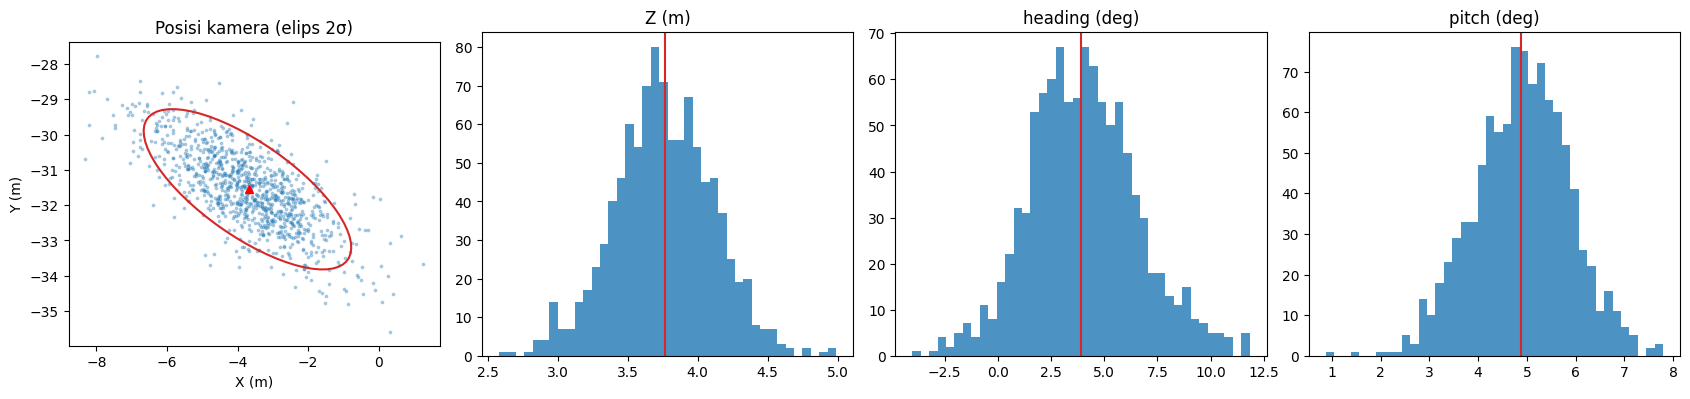

In [60]:
def cov_ellipse(ax, xy, n_std=2.0, **kw):
    vals, vecs = np.linalg.eigh(np.cov(xy.T))
    ang = math.degrees(math.atan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * n_std * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(xy.mean(0), w, h, angle=ang, fill=False, **kw))


fig, axes = plt.subplots(1, 4, figsize=(17, 4))
ax = axes[0]
ax.scatter(mc_all.X.to_numpy(), mc_all.Y.to_numpy(), s=3, alpha=0.3)
cov_ellipse(ax, mc_all[["X", "Y"]].to_numpy(), color="tab:red", lw=1.5)
ax.plot(C_W[0], C_W[1], "r^"); ax.set_aspect("equal"); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
ax.set_title("Posisi kamera (elips 2σ)")
for ax, col, unit in zip(axes[1:], ["Z", "heading", "pitch"], ["m", "deg", "deg"]):
    ax.hist(mc_all[col].to_numpy(), bins=40, color="tab:blue", alpha=0.8); ax.axvline(pose[col], color="tab:red")
    ax.set_title(f"{col} ({unit})")
plt.tight_layout(); plt.show()

### 10.3 Konsistensi denah untuk *gate* jauh

Setiap *gate* tunggal dapat di-*solve* sendiri dengan PnP planar (IPPE/SQPnP) hanya dari dimensinya sendiri, tanpa denah. Hasilnya adalah posisi tiap *gate* dalam *camera frame*. Jarak antar-*gate* yang diperoleh tidak bergantung pada pose maupun denah, sehingga dapat dibandingkan langsung dengan denah.

TG     : 8 titik, RMS 0.76 px, jarak dari kamera 33.5 m
SG_far : 8 titik, RMS 0.97 px, jarak dari kamera 45.9 m
SG_a   : 8 titik, RMS 0.74 px, jarak dari kamera 41.4 m
SG_b   : 5 titik, RMS 0.99 px, jarak dari kamera 52.9 m


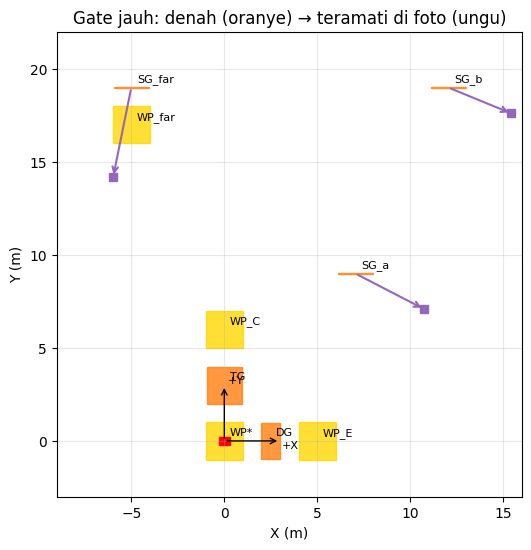

,dari foto (m),dari denah (m),selisih (m)
pasangan,,,
TG – SG_far,13.98,17.72,-3.74
TG – SG_a,12.15,9.93,2.22
TG – SG_b,22.34,20.83,1.51
SG_far – SG_a,18.16,15.66,2.51
SG_far – SG_b,21.70,17.05,4.65
SG_a – SG_b,11.53,11.18,0.35


In [61]:
def local_gate_pose(obj, centre):
    ids = [i for i in corr.index if corr.loc[i, "objek"] == obj and "_" in i and i.split("_")[-1] in FRAME]
    if obj == "TG":
        ids = [i for i in ids if i != "TG_bTL"]
    X = corr.loc[ids, ["X", "Y", "Z"]].to_numpy(float) - centre
    s = solve_pose(X, corr.loc[ids, ["u", "v"]].to_numpy(float), K)
    return s["t"], s["rms"], len(ids)


centres = {"TG": np.array([plan.loc["TG", "X"], plan.loc["TG", "Y"] - 1.0, 0.0])}
centres.update({g: np.array([plan.loc[g, "X"], plan.loc[g, "Y"], 0.0]) for g in ["SG_far", "SG_a", "SG_b"]})
cam_pos = {}
for g, c in centres.items():
    cam_pos[g], rms_g, n_g = local_gate_pose(g, c)
    print(f"{g:7s}: {n_g} titik, RMS {rms_g:.2f} px, jarak dari kamera {np.linalg.norm(cam_pos[g]):.1f} m")

names = list(centres)
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = names[i], names[j]
        obs_d = np.linalg.norm(cam_pos[a] - cam_pos[b]); plan_d = np.linalg.norm(centres[a] - centres[b])
        pairs.append((f"{a} – {b}", obs_d, plan_d, obs_d - plan_d))
pairs = pd.DataFrame(pairs, columns=["pasangan", "dari foto (m)", "dari denah (m)", "selisih (m)"]).set_index("pasangan")

# posisi terpasang gate jauh menurut foto, dinyatakan pada world frame dengan pose klaster dekat
asbuilt = {g: R_CW.T @ (cam_pos[g] - T_CW) for g in ["SG_far", "SG_a", "SG_b"]}
fig, ax = plt.subplots(figsize=(6, 6.5))
draw_plan_topdown(ax, plan)
for g, p in asbuilt.items():
    ax.annotate("", xy=p[:2], xytext=centres[g][:2], arrowprops=dict(arrowstyle="->", color="tab:purple", lw=1.5))
    ax.plot(*p[:2], "s", color="tab:purple", ms=6)
ax.set_xlim(-9, 16); ax.set_ylim(-3, 22); ax.set_title("Gate jauh: denah (oranye) → teramati di foto (ungu)")
plt.show()
pairs.round(2)

Jarak antar-*gate* menurut foto berbeda 1.5-4.7 m dari denah. Kesalahan panjang fokus tidak dapat menjelaskannya: kesalahan $f$ mengubah semua jarak dengan faktor yang sama, sedangkan di sini perbandingannya pun tidak cocok. Jarak antara TG ke SG_far lebih pendek dari denah, sementara jarak TG ke SG_a lebih panjang. Karena *gate* fisik tidak berubah ukuran, penjelasan yang paling mungkin adalah *gate* jauh tidak dipasang tepat sesuai denah. Penyebab tambahan yang mungkin adalah tanah yang tidak rata pada jarak 45-50 m. Seandainya *gate* jauh dipaksa memakai posisi denahnya, PnP gabungan menghasilkan error RMS puluhan piksel dan pose yang bias. 

### 10.4 Sumber error

1. **Penempatan terpasang vs denah (dominan).** Posisi absolut kamera hanya sebaik posisi TG/DG relatif terhadap WP\* (A3, A6). Ini adalah sumber terbesar pada $X$ dan $Y$ di tabel sensitivitas.
2. **Baseline area yang pendek** (~4 m pada ~33 m). Kedalaman ($Y$), tinggi ($Z$), dan *pitch* menjadi komponen terlemah. Bias di $Y$ dan $Z$ saling terkait: kamera yang sedikit lebih dekat dan lebih rendah menghasilkan gambar yang hampir sama.
3. **Panjang fokus dari EXIF** menjadi ~2 % jarak, kira-kira ~0,6 m di $Y$.
4. ***Principal point*** tidak dikalibrasi, sehingga *heading* dan *pitch* memiliki bias sekitar 0.5 derajat.
5. **Ekstraksi 2D:** ukura objek hanya 100-170 px di gambar. Tepi atas-dalam TG bertumpuk dengan rangka belakang, dan rangka jauh DG hanya ~4 px lebar.
6. **Bentuk objek nyata tidak sama dengan denah:** panel samping turun hingga ke tanah, bentuk bisa melengkung (tepi atas jauh DG terlihat miring), dan kotak merah meruncing ke bawah.
7. **Distorsi lensa** diasumsikan sudah dikoreksi. Semua titik berada dekat pusat gambar (< 500 px), sehingga efek distorsi residual kecil.

In [62]:
summary = pd.DataFrame({
    "estimasi": pd.Series(pose)[COLS],
    "±1σ (Monte Carlo)": mc_all[COLS].std(),
    "sumber dominan": sensitivity.drop("SEMUA").idxmax().rename(lambda c: c.removeprefix("σ_")),
})
summary.index = ["X (m)", "Y (m)", "Z / tinggi (m)", "heading (deg)", "pitch (deg)", "roll (deg)"]
summary.round(2)

,estimasi,±1σ (Monte Carlo),sumber dominan
X (m),-3.69,1.47,DG_vs_TG
Y (m),-31.53,1.14,DG_vs_TG
Z / tinggi (m),3.77,0.35,DG_vs_TG
heading (deg),3.93,2.54,DG_vs_TG
pitch (deg),4.87,0.98,principal_point
roll (deg),0.28,0.89,DG_vs_TG


## 11. Kesimpulan

Relatif terhadap pusat WP yang berisi kotak merah (*world frame*: $X$ ke kanan, $Y$ menuju TG, $Z$ ke atas), foto diambil dari

$$C_{approx} (-3.7 \pm 1.4,\ -31.5 \pm 1.1,\ 3.8 \pm 0.4)\ \text{m},$$

yaitu **sekitar 32 m di depan WP\*** (atau sekitar 20 m di luar garis batas lapangan pada denah), sedikit ke kiri, dan **sekitar 3.8 m di atas permukaan lapangan**. Ketinggian ini cocok dengan narasi awal bahwa kamera berdiri di platform yang lebih tinggi dari lapangan, di balik pagar kayu yang terlihat di latar depan foto. Orientasinya sebagai berikut: 
* ***heading* $\approx +4.0^\circ \pm 2.4^\circ$** (hampir lurus ke arena, sedikit menoleh ke kanan), 
* ***pitch* $\approx +4.9^\circ \pm 1.0^\circ$** (sedikit mendongak), 
* ***roll* $\approx 0.3^\circ \pm 0.9^\circ$** (ponsel tegak).

Bukti:
1. Tiga solver PnP yang berbeda konvergen ke pose yang sama.
2. Reproyeksi model menutupi kedua *gate* (RMS 2,3 px).
3. Kotak merah dan WP\*, yang **tidak ikut** dihitung, jatuh dalam $0.2 - 0.5$ m dari posisi denahnya.
4. Tidak ada satu titik yang menggeser pose lebih dari 0.3 m.

Risiko terbesar adalah asumsi bahwa area TG-DG-WP\* terpasang sesuai denah. Ketidakcocokan TG-DG beberapa puluh cm sudah tampak pada residual, dan itulah yang mendominasi ketidakpastian.


Pemeriksaan lanjutan:

1. Ukur jarak TG-DG-WP\* di lapangan dengan pita ukur untuk menghapus sumber `DG_vs_TG`, sekaligus memungkinkan *gate* jauh dipakai kembali setelah posisi terpasangnya diukur.
2. Kalibrasi kamera ponsel (*checkerboard*, mode dan lensa yang sama) untuk fokus, *principal point*, dan distorsi.
3. Ambil foto kedua dari arah berbeda dan *solve* secara bersama.
4. Ambil koordinat geografis  WP\* agar posisi dapat dinyatakan sebagai lintang/bujur.